In [1]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

# Реализовать преобразование Хаара (3 ступени сжатия).

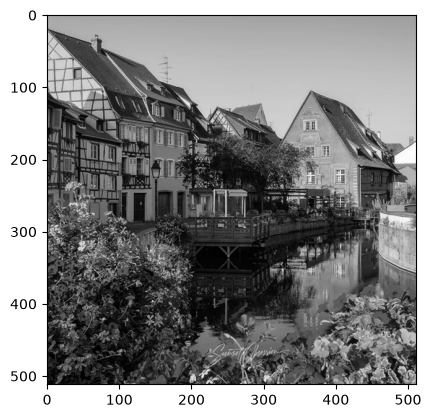

In [29]:
img = cv.imread('img6.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2GRAY).astype(np.float32)
img = cv.resize(img, (512, 512))

plt.imshow(img, cmap="gray")

In [30]:
def haar_step(block):
    a = block[0::2, 0::2]
    b = block[0::2, 1::2]
    c = block[1::2, 0::2]
    d = block[1::2, 1::2]

    mean  = (a + b + c + d) / 4
    vert  = (a - b + c - d) / 4
    horiz = (a + b - c - d) / 4
    diag  = (a - b - c + d) / 4
    return mean, vert, horiz, diag

current = img
levels = []
for lvl in range(3):
    mean, vert, horiz, diag = haar_step(current)
    levels.append((mean, vert, horiz, diag))
    current = mean

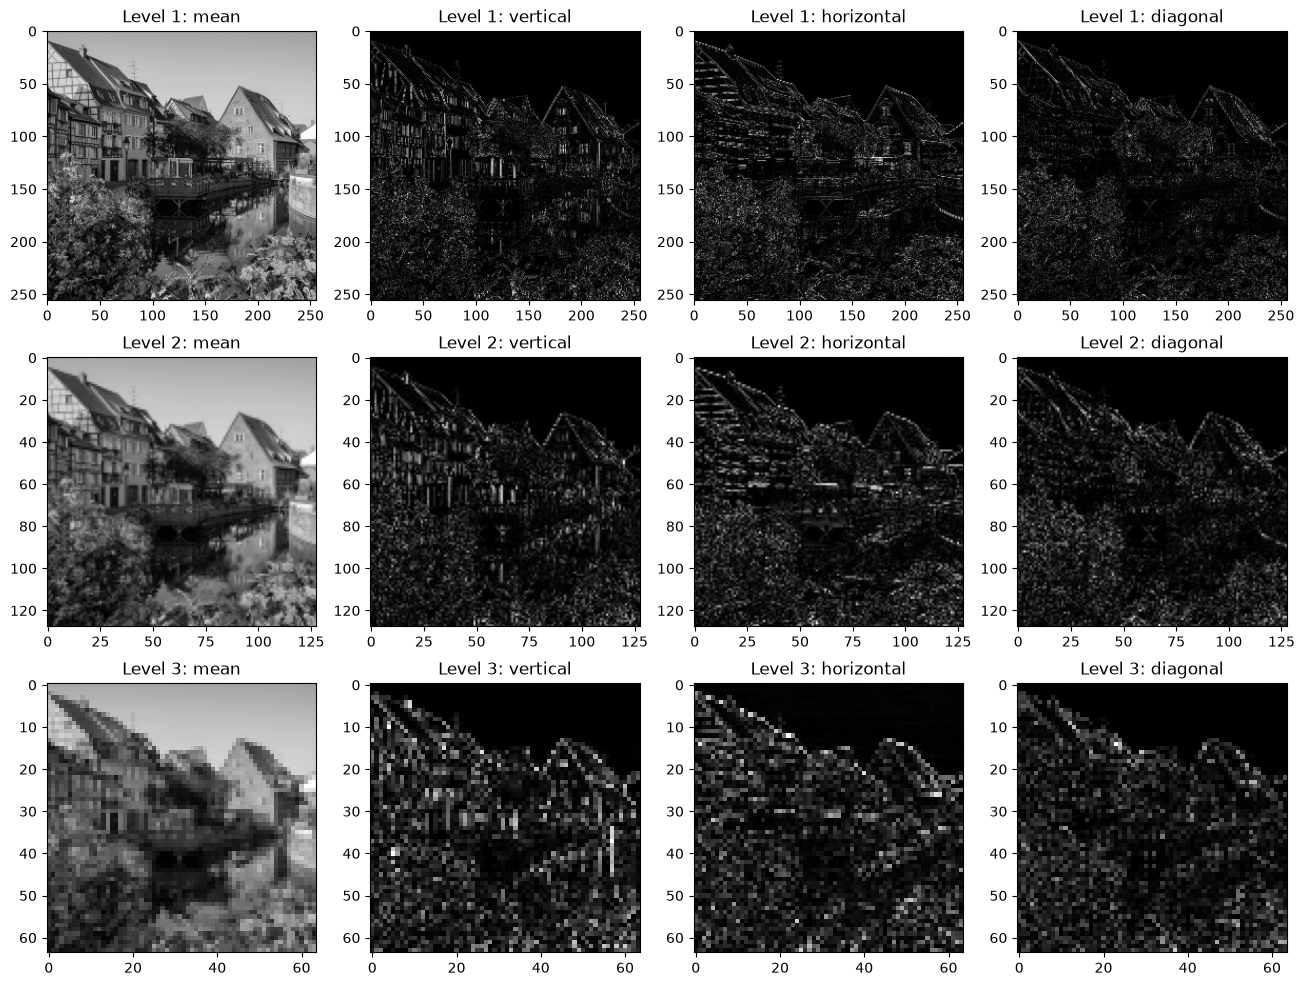

In [31]:
fig, ax = plt.subplots(3, 4, figsize=(16, 12))

for i, (m, v, h, d) in enumerate(levels):
    ax[i][0].imshow(np.abs(m), cmap='gray'); ax[i][0].set_title(f'Level {i+1}: mean')
    ax[i][1].imshow(np.abs(v), cmap='gray'); ax[i][1].set_title(f'Level {i+1}: vertical')
    ax[i][2].imshow(np.abs(h), cmap='gray'); ax[i][2].set_title(f'Level {i+1}: horizontal')
    ax[i][3].imshow(np.abs(d), cmap='gray'); ax[i][3].set_title(f'Level {i+1}: diagonal')

plt.show()